In [280]:
fl  = 'R1233zd(E)'
cpw = 4180.0
T_DC_out = 60 + 273.15 # Water temp. coming out of DC (K)
m_w = 28.7 # Water loop flow rate for DC cooling (kg/s) 
PP, SH, SC = 5.0, 4.0, 0 # Pinch (K), superheat (K), subcool (K)
eta_t, eta_p = 0.8, 0.75 # Efficiencies of ORC turbine and pump

def orc(T_evap, T_cond):
    P_e, P_c = PS('P','T',T_evap,'Q',1,fl), PS('P','T',T_cond,'Q',1,fl) # Gives evaporator and condenser pressures - check if this should be 0 for saturated liquid

    # 1: pump inlet (sat. liquid at T_cond, minus subcooling)
    T1 = T_cond - SC # Pump inlet temp.
    h1 = PS('H','T',T1,'Q',0,fl);  s1 = PS('S','T',T1,'Q',0,fl) # Enthalpy and entropy at pump inlet
    
    # 2: pump exit
    h2_ideal = PS('H','P',P_e,'S',s1,fl) # Calculates the enthalpy at pump exit if it were isentropic (pump just increases pressure from P_c to P_e and entropy stays the same)
    h2 = h1 + (h2_ideal - h1)/eta_p # Calculates the actual enthalpy at pump exit, accounting for pump efficiency (note, isentropic efficiency is used)
    
    # 3: WF liquid preheated to evaporation temperature
    h3 = PS('H','T',T_evap,'Q',0,fl)  # Enthalpy of saturated liquid at evaporator temperature
    
    # 4: turbine inlet
    h4 = PS('H','T',T_evap+SH,'P',P_e,fl);  s4 = PS('S','T',T_evap+SH,'P',P_e,fl) # Calculates the enthalpy and entropy at turbine inlet (superheated vapor)
    
    # 5: turbine outlet
    h5_ideal = PS('H','P',P_c,'S',s4,fl) # Calculates the enthalpy at turbine exit if it were isentropic (turbine just decreases pressure from P_e to P_c and entropy stays the same)
    h5   = h4 - eta_t*(h4 - h5_ideal) # Calculates the actual enthalpy at turbine exit, accounting for turbine efficiency (note, isentropic efficiency is used)

    # pinch at bubble point: water temp there = T_evap + PP
    Q_boil = m_w*cpw*(T_DC_out - (T_evap+PP)) # Heat for boiling + superheat in kW (note the evaporator is counter-flow, so water first superheats + boils the working fluid, then preheats it)
    m_wf = Q_boil/(h4 - h3) # mass flow rate of working fluid in the ORC loop
    Q_in = m_wf*(h4 - h2) # Heat delivered to the ORpinchC working fluid in the evaporator in kW
    T_w_out_evap = T_DC_out - Q_in/(m_w*cpw) # check To >= T_evap-ish and cold-end pinch

    W_t, W_p = m_wf*(h4-h5), m_wf*(h2-h1)    # Work output from turbine and work input to pump
    Q_cond = m_wf*(h5 - h1) # Heat rejected to the condenser
    return dict(m_wf=m_wf, Q_in=Q_in, T_w_out_evap=T_w_out_evap, W_net=W_t-W_p, Q_cond=Q_cond, ORC_efficiency=100*(W_t-W_p)/Q_in)

In [ ]:
# Module-level assumptions (one place, easy to vary in sensitivity runs)
rho_w, dp, eta_m, eta_imp = 1000.0, 100e3, 0.9, 0.78
dp_air, eta_fan, eta_motor_fan = 120.0, 0.65, 0.90   # placeholders, need sources
dT_air_exit = 2.0        # K, exit air below hot water temperature
dT_hx_min = 3.0          # K, minimum approach in the DC/tower-loop heat exchanger (placeholder)
h_fg = 2.4e6             # J/kg, only if you need it elsewhere

def wet_tower(Q, T_db_amb, T_wb_amb, P_atm, T_approach_wt, T_range_wt):
    """Open wet tower rejecting Q (W). Temperatures in K, P in Pa."""
    if Q <= 0:
        return dict(Q=0.0, m_water=0.0, m_air=0.0, LG=np.nan, W_pump=0.0,
                    W_fan=0.0, evap_kg_s=0.0)
    h_in = HAPropsSI('H', 'T', T_db_amb, 'Twb', T_wb_amb, 'P', P_atm)
    Humidity_in = HAPropsSI('W', 'T', T_db_amb, 'Twb', T_wb_amb, 'P', P_atm)
    v_da = HAPropsSI('Vda', 'T', T_db_amb, 'Twb', T_wb_amb, 'P', P_atm)

    T_hot = T_wb_amb + T_approach_wt + T_range_wt          # water entering the tower
    T_air_out = T_hot - dT_air_exit
    h_out = HAPropsSI('H', 'T', T_air_out, 'R', 1.0, 'P', P_atm)
    Humidity_out = HAPropsSI('W', 'T', T_air_out, 'R', 1.0, 'P', P_atm)

    dh = h_out - h_in
    if dh <= 0:
        raise ValueError("Exit air enthalpy not above inlet")
    m_air = Q / dh                                # kg/s dry air
    m_water = Q / (cpw * T_range_wt)                 # kg/s
    W_pump = (m_water / rho_w) * dp / (eta_m * eta_imp)
    W_fan = m_air * v_da * dp_air / (eta_fan * eta_motor_fan)
    return dict(Q=Q, m_water=m_water, m_air=m_air, LG=m_water / m_air,
                W_pump=W_pump, W_fan=W_fan, evap_kg_s=m_air * (Humidity_out - Humidity_in))

4088.3190883190878


In [ ]:
def calculate_system_performance(T_evap_C, T_cond_C, T_db_amb, T_wb_amb, P_atm,
                                 T_approach=4.0, T_range=5.0):
    T_evap, T_cond = T_evap_C + 273.15, T_cond_C + 273.15

    # 1. ORC
    res = orc(T_evap, T_cond)
    W_net_orc, Q_cond, Q_in = res['W_net'], res['Q_cond'], res['Q_in']
    T_w_out_evap, ORC_eff = res['T_w_out_evap'], res['ORC_efficiency']

    # 2. DC loop and trim duty (heat exchanger duty, DC side)
    T_DC_return = 40.0 + 273.15
    Q_trim = max(m_w * cpw * (T_w_out_evap - T_DC_return), 0.0)

    # 3. Heat-exchanger feasibility (counterflow), tower loop at same approach/range
    T_cw_c = T_wb_amb + T_approach            # tower-loop water leaving the tower
    T_cw_h = T_cw_c + T_range                 # tower-loop water leaving the HX
    if Q_trim > 0:
        gap_cold = T_DC_return - T_cw_c       # DC cold end vs tower-loop cold end
        gap_hot = T_w_out_evap - T_cw_h       # DC hot end vs tower-loop hot end
        if min(gap_cold, gap_hot) < dT_hx_min:
            raise ValueError("Heat exchanger approach too small")

    # 4. Towers (same function for condenser, trim and baseline)
    cond = wet_tower(Q_cond, T_db_amb, T_wb_amb, P_atm, T_approach, T_range)
    trim = wet_tower(Q_trim, T_db_amb, T_wb_amb, P_atm, T_approach, T_range)
    Q_base = m_w * cpw * (T_DC_out - T_DC_return)      # check if this base case is needed??
    base = wet_tower(Q_base, T_db_amb, T_wb_amb, P_atm, T_approach, T_range)


    # 5. DC loop pump (needed in both cases)
    W_pump_DC = (m_w / rho_w) * dp / (eta_m * eta_imp)

    # 6. Carnot (kelvin, maximum cycle temperature = turbine inlet)
    eta_carnot_ORC = (1.0 - T_cond / (T_evap + SH)) * 100.0
    eta_carnot_broad = (1.0 - T_wb_amb / (60.0 + 273.15)) * 100.0

    # 7. Power accounting
    orc_cooling = cond['W_pump'] + cond['W_fan']        # only exists because of the ORC
    trim_power = trim['W_pump'] + trim['W_fan']
    base_power = base['W_pump'] + base['W_fan']
    total_parasitics = orc_cooling + trim_power + W_pump_DC
    W_net_system = W_net_orc - total_parasitics
    # benefit vs no-recovery baseline: DC pump cancels, trim power is compared
    W_net_benefit = W_net_orc - orc_cooling - (trim_power - base_power)

    return {
        'W_net_orc': W_net_orc, 'W_net_system': W_net_system, 'Q_in': Q_in,
        'W_net_benefit': W_net_benefit, 'total_parasitics': total_parasitics,
        'Q_cond': Q_cond, 'Q_trim': Q_trim, 'T_w_out_evap': T_w_out_evap,
        'ORC_actual_efficiency': ORC_eff,
        'ORC_carnot_efficiency': eta_carnot_ORC,
        'broad_carnot_efficiency': eta_carnot_broad,
        'LG_cond': cond['LG'], 'LG_trim': trim['LG'], 'LG_base': base['LG'],
        'W_fan_cond': cond['W_fan'], 'W_pump_cond': cond['W_pump'],
        'W_fan_trim': trim['W_fan'], 'W_pump_trim': trim['W_pump'],
        'W_pump_DC': W_pump_DC,
        'water_cond_L_h': cond['evap_kg_s'] * 3600.0,
        'water_trim_L_h': trim['evap_kg_s'] * 3600.0,
        'water_base_L_h': base['evap_kg_s'] * 3600.0,
        'water_ORC_case_L_h': (cond['evap_kg_s'] + trim['evap_kg_s']) * 3600.0,
    }

4088.3190883190878


In [292]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from CoolProp.CoolProp import PropsSI as PS
from CoolProp.HumidAirProp import HAPropsSI

# Assumes these are already defined in earlier cells: fl, PP, SH, T_DC_out,
# orc(), m_w, cpw, and calculate_system_performance()

# 1. Weather bin data
weather_df = pd.DataFrame({
    'T_db': [-2, 0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46],
    'T_wb': [-11.6, -6.7, -3.9, -2.1, -0.1, 2.2, 3.9, 4.9, 6.0, 7.3, 8.5, 10.0, 11.5, 12.7, 13.6, 14.6, 15.7, 17.0, 18.3, 18.9, 19.7, 19.6, 20.4, 21.5, 21.9],
    'hours': [14, 50, 126, 215, 310, 471, 528, 527, 564, 544, 516, 543, 525, 570, 535, 540, 470, 370, 332, 271, 250, 212, 178, 93, 6]
})

P_atm, T_approach, T_range, T_PP_condensor = 94100.0, 4.0, 5.0, 5.0
CLIP_WB = True    # [C9] True: raise impossible wet-bulbs to the physical minimum; False: leave those bins unevaluated (NaN)

# ======================= CONSTRAINTS ON THE OPTIMISER =======================
T_evap_max_C   = (T_DC_out - 273.15) - PP - SH               # [C1] hot-end pinch limit
T_cond_floor_C = PS('T','P',P_atm,'Q',0,fl) - 273.15          # [C2] condenser >= atmospheric pressure
DT_EVAP_MIN    = 5.0                                          # [C3] T_evap >= T_cond + 5 K
T_EVAP_STEP    = 0.5                                          # [C4] search resolution (K)
print("[C2] condenser floor (C):", T_cond_floor_C, "| [C1] max T_evap (C):", T_evap_max_C)

failed, results_list = [], []

for _, row in weather_df.iterrows():
    T_db_C, T_wb_raw_C, bin_hours = row['T_db'], row['T_wb'], row['hours']
    T_db_amb = T_db_C + 273.15

    # ---- [C9] DATA CORRECTION (optional): wet-bulb cannot be below the dry-air limit ----
    T_wb_min_C = HAPropsSI('Twb','T',T_db_amb,'R',0.01,'P',P_atm) - 273.15
    wb_impossible = T_wb_raw_C < T_wb_min_C
    T_wb_C = max(T_wb_raw_C, T_wb_min_C) if CLIP_WB else T_wb_raw_C
    T_wb_amb = T_wb_C + 273.15

    # ---- [C2] condenser floor applied here ----
    T_cond_weather_C = T_wb_C + T_approach + T_range + T_PP_condensor
    T_cond_C = max(T_cond_weather_C, T_cond_floor_C)

    # ---- Broad Carnot efficiency: heat source (water leaving the data centre) and
    #      ambient wet-bulb as the two reservoirs, absolute temperatures (K), in % ----
    broad_carnot = (1.0 - T_wb_amb / T_DC_out) * 100.0

    best = None
    n_eval = n_fail = n_nonpos = n_carnot = 0

    # ---- [C3] lower bound, [C1] upper bound, [C4] step ----
    for T_evap_C in np.arange(T_cond_C + DT_EVAP_MIN, T_evap_max_C + 1e-9, T_EVAP_STEP):
        try:
            res = calculate_system_performance(T_evap_C, T_cond_C, T_db_amb, T_wb_amb, P_atm,
                                               T_approach, T_range)
            # add ", PP_cond=T_PP_condensor" to this call if you have applied the [C10] tower setpoint fix
        except Exception as e:                                  # [C7] dropped, but recorded
            failed.append((T_db_C, T_evap_C, repr(e)))
            n_fail += 1
            continue
        n_eval += 1
        # [C5] requires a finite result and positive ORC block output.
        # Negative W_net_system is NOT discarded.
        if not np.isfinite(res['W_net_system']) or res['W_net_orc'] <= 0:
            n_nonpos += 1
            continue
        if res['ORC_actual_efficiency'] > res['ORC_carnot_efficiency']:     # [C6]
            n_carnot += 1
            continue
        if best is None or res['W_net_system'] > best[0]:
            best = (res['W_net_system'], T_evap_C, res)

    # ---- [C8 REMOVED] negative values are kept. ----
    # A bin with no valid design at all is NaN (not evaluated), not 0 kW.
    if best is not None:
        net_W, T_evap_opt, res = best
        no_valid_design = False
    else:
        net_W, T_evap_opt, res = np.nan, np.nan, None
        no_valid_design = True

    results_list.append({
        'T_db_bin': T_db_C, 'T_wb_bin': T_wb_raw_C, 'T_wb_used_C': T_wb_C,
        'T_cond_C': T_cond_C, 'TMY_hours': bin_hours, 'Optimal_T_evap_C': T_evap_opt,
        'W_net_orc_kW': res['W_net_orc']/1e3 if res else np.nan,
        'W_net_system_kW': net_W/1e3,                       # may be negative
        'Total_Parasitics_kW': res['total_parasitics']/1e3 if res else np.nan,
        'Annual_Net_Energy_MWh': net_W*bin_hours/1e6,       # negative = net consumption
        # ---- efficiencies (all in %) ----
        'ORC_actual_efficiency': res['ORC_actual_efficiency'] if res else np.nan,
        'ORC_carnot_efficiency': res['ORC_carnot_efficiency'] if res else np.nan,   # T_cond to T_evap+SH
        'broad_carnot_efficiency': broad_carnot,                                    # 60 C source to wet-bulb
        'ORC_frac_of_broad_carnot': (res['ORC_actual_efficiency']/broad_carnot) if res else np.nan,
        # ---- diagnostics: which measure is active in this bin ----
        'flag_wb_impossible': wb_impossible,
        'flag_cond_floor_C2': T_cond_weather_C < T_cond_floor_C,
        'flag_at_Tevap_max_C1': (not no_valid_design) and (T_evap_opt >= T_evap_max_C - T_EVAP_STEP),
        'flag_no_valid_design': no_valid_design,
        'n_evaluated': n_eval, 'n_failed_C7': n_fail,
        'n_nonpositive_C5': n_nonpos, 'n_carnot_C6': n_carnot,
                # ---- water at the optimum design (L/h while operating) ----
        'water_cond_L_h': res['water_cond_L_h'] if res else np.nan,
        'water_trim_L_h': res['water_trim_L_h'] if res else np.nan,
        'water_ORC_case_L_h': res['water_ORC_case_L_h'] if res else np.nan,
        # inlet relative humidity of the air (diagnostic, shows the bin dependence)
        'RH_in_pct': HAPropsSI('R', 'T', T_db_amb, 'Twb', T_wb_amb, 'P', P_atm) * 100.0,
    })

bin_results_df = pd.DataFrame(results_list)
print(len(failed), "failed evaluations;", Counter(f[2][:60] for f in failed).most_common(3))
print(bin_results_df[['T_db_bin','Optimal_T_evap_C','W_net_orc_kW','W_net_system_kW',
                      'ORC_actual_efficiency','ORC_carnot_efficiency',
                      'broad_carnot_efficiency','ORC_frac_of_broad_carnot']])


[C2] condenser floor (C): 16.18161990571747 | [C1] max T_evap (C): 51.0
0 failed evaluations; []
    T_db_bin  Optimal_T_evap_C  W_net_orc_kW  W_net_system_kW  \
0       -2.0          37.18162    122.998877        66.605154   
1        0.0          37.18162    122.998877        67.464688   
2        2.0          37.18162    122.998877        69.657302   
3        4.0          37.18162    122.998877        70.840574   
4        6.0          37.18162    122.998877        72.210328   
5        8.0          37.20000    122.864845        75.661079   
6       10.0          37.40000    112.194641        66.498952   
7       12.0          37.40000    106.099538        61.032810   
8       14.0          37.50000     99.441349        55.082720   
9       16.0          38.30000     91.798864        48.298922   
10      18.0          39.00000     85.034113        42.317808   
11      20.0          39.50000     77.008238        35.287317   
12      22.0          40.50000     69.377757        28.636

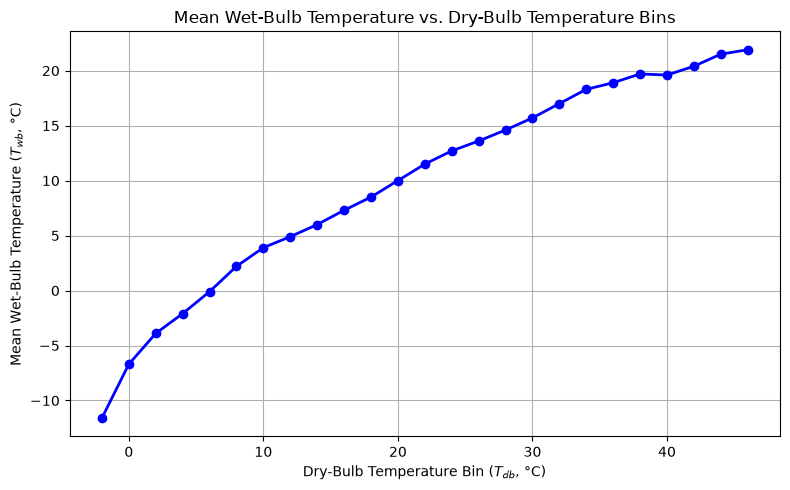

In [293]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(bin_results_df['T_db_bin'], bin_results_df['T_wb_bin'], marker='o', color='b', linestyle='-', linewidth=2)
plt.title('Mean Wet-Bulb Temperature vs. Dry-Bulb Temperature Bins')
plt.xlabel('Dry-Bulb Temperature Bin ($T_{db}$, °C)')
plt.ylabel('Mean Wet-Bulb Temperature ($T_{wb}$, °C)')
plt.grid(True)
plt.tight_layout()
plt.show()

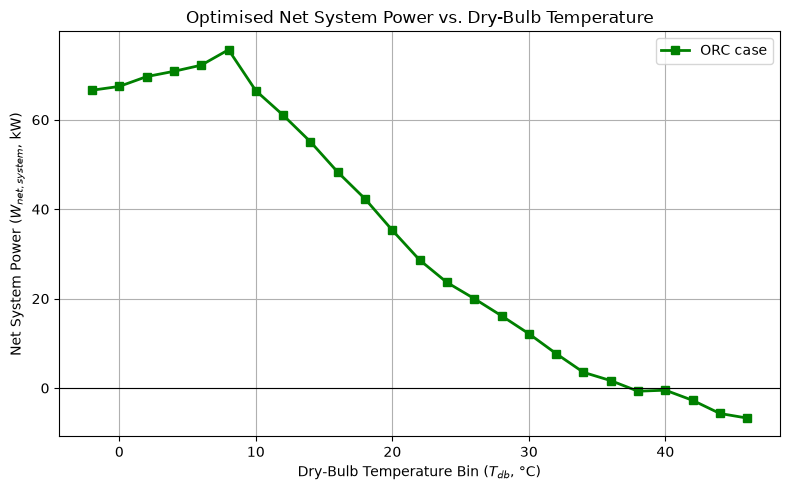

In [294]:
# 2. Plot (negative values shown as negative)
plt.figure(figsize=(8, 5))
plt.plot(bin_results_df['T_db_bin'], bin_results_df['W_net_system_kW'],
         marker='s', color='g', linewidth=2, label='ORC case')
# plt.plot(base_df['T_db_bin'], base_df['W_net_kW'], marker='o', color='gray', label='Baseline')  # colleague's baseline, same sign convention
plt.axhline(0, color='k', linewidth=0.8)
plt.xlabel('Dry-Bulb Temperature Bin ($T_{db}$, °C)')
plt.ylabel('Net System Power ($W_{net, system}$, kW)')
plt.title('Optimised Net System Power vs. Dry-Bulb Temperature')
plt.grid(True); plt.legend(); plt.tight_layout(); plt.show()

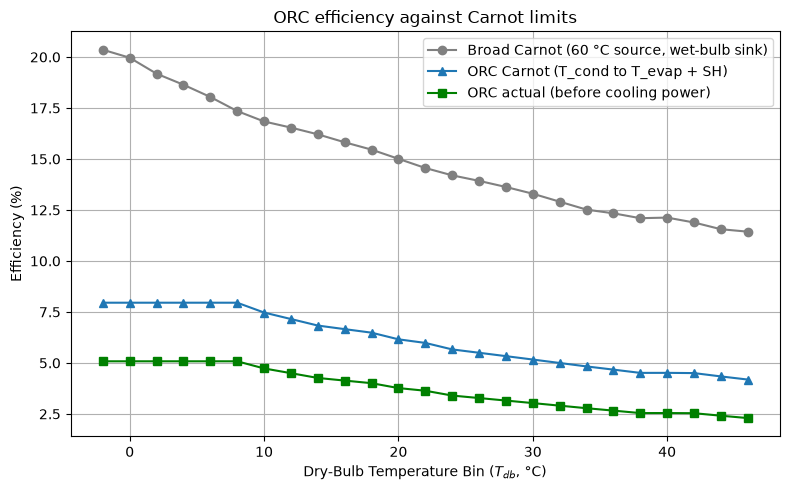

In [295]:
# 3. Efficiency comparison plot
plt.figure(figsize=(8, 5))
plt.plot(bin_results_df['T_db_bin'], bin_results_df['broad_carnot_efficiency'],
         marker='o', color='gray', label='Broad Carnot (60 °C source, wet-bulb sink)')
plt.plot(bin_results_df['T_db_bin'], bin_results_df['ORC_carnot_efficiency'],
         marker='^', color='tab:blue', label='ORC Carnot (T_cond to T_evap + SH)')
plt.plot(bin_results_df['T_db_bin'], bin_results_df['ORC_actual_efficiency'],
         marker='s', color='g', label='ORC actual (before cooling power)')
plt.xlabel('Dry-Bulb Temperature Bin ($T_{db}$, °C)')
plt.ylabel('Efficiency (%)')
plt.title('ORC efficiency against Carnot limits')
plt.grid(True); plt.legend(); plt.tight_layout(); plt.show()

In [296]:
# 1. Sort the results dataframe by performance (highest net power first)
# This ensures that if we have to drop hours, we drop the least productive bins
bin_results_sorted = bin_results_df.sort_values(by='W_net_system_kW', ascending=False).reset_index(drop=True)

# 2. Accumulate hours up to the 8,000-hour limit
target_hours = 8000
accumulated_hours = 0
active_bins_list = []

for index, row in bin_results_sorted.iterrows():
    hours_in_bin = row['TMY_hours']
    
    if accumulated_hours + hours_in_bin <= target_hours:
        # Take the whole bin
        active_bins_list.append(row)
        accumulated_hours += hours_in_bin
    else:
        # Take only the partial hours needed from this bin to hit exactly 8,000 hours
        partial_hours = target_hours - accumulated_hours
        if partial_hours > 0:
            row_partial = row.copy()
            row_partial['TMY_hours'] = partial_hours
            # Recalculate annual energy for these partial hours
            row_partial['Annual_Net_Energy_MWh'] = (row_partial['W_net_system_kW'] * 1e3 * partial_hours) / 1e6
            active_bins_list.append(row_partial)
            accumulated_hours += partial_hours
        break  # Reached 8,000 hours

# 3. Create the final restricted 8,000-hour DataFrame
operating_df = pd.DataFrame(active_bins_list)

# 4. Calculate total annual figures
total_annual_generation_MWh = operating_df['Annual_Net_Energy_MWh'].sum()
total_active_hours = operating_df['TMY_hours'].sum()

print(f"--- 8,000-Hour Operating Constraint Summary ---")
print(f"Total Active Operating Hours: {total_active_hours} hours")
print(f"Total Annual Net Energy Generated: {total_annual_generation_MWh:,.2f} MWh/year")

# (Optional) View which lowest-producing bins or partial hours were cut
omitted_bins = bin_results_sorted.iloc[len(operating_df):]
if not omitted_bins.empty:
    print(f"\nOmitted or partially trimmed bins (lowest production):")
    print(omitted_bins[['T_db_bin', 'T_wb_bin', 'TMY_hours', 'W_net_system_kW']])

--- 8,000-Hour Operating Constraint Summary ---
Total Active Operating Hours: 8000.0 hours
Total Annual Net Energy Generated: 310.03 MWh/year

Omitted or partially trimmed bins (lowest production):
    T_db_bin  T_wb_bin  TMY_hours  W_net_system_kW
20      40.0      19.6      212.0        -0.469711
21      38.0      19.7      250.0        -0.703558
22      42.0      20.4      178.0        -2.739748
23      44.0      21.5       93.0        -5.683462
24      46.0      21.9        6.0        -6.710443


--- Annual water use (ORC case, evaporation only) ---
Evaporation: 29,924 m3/yr
WUE_site: 1.25 L/kWh IT  (IT load 2,999 kW)
Check: heat/h_fg estimate = 28,791,840 L vs model 29,924,084 L
    T_db_bin  T_wb_bin  RH_in_pct  TMY_hours  water_ORC_case_L_h        evap_L
5       -2.0     -11.6   1.000000       14.0         2940.343743  4.116481e+04
4        0.0      -6.7   1.000000       50.0         3159.446043  1.579723e+05
3        2.0      -3.9  18.012481      126.0         2991.240581  3.768963e+05
2        4.0      -2.1  23.217936      215.0         3054.349961  6.566852e+05
1        6.0      -0.1  30.131495      310.0         3061.818117  9.491636e+05
0        8.0       2.2  34.129119      471.0         3013.810702  1.419505e+06
6       10.0       3.9  35.784028      528.0         3077.464525  1.624901e+06
7       12.0       4.9  31.195235      527.0         3294.344615  1.736120e+06
8       14.0       6.0  28.262904      564.0         3477.439183  1.961276e+06
9       16.0       7.3 

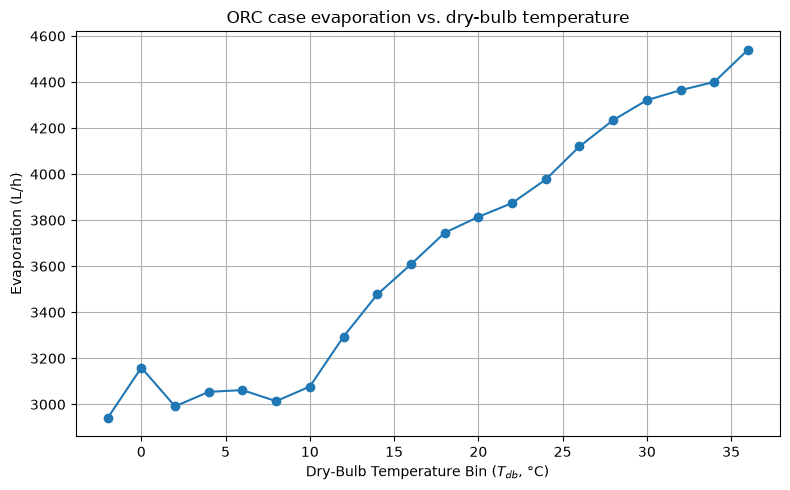

In [297]:
# ======================= ANNUAL WATER USE (evaporation only) =======================
RECOVERABLE_FRAC = 0.8   # brief's starting assumption: recoverable heat = 0.8 x IT electricity

needed = ['TMY_hours', 'water_cond_L_h', 'water_trim_L_h', 'water_ORC_case_L_h', 'RH_in_pct']
missing = [c for c in needed if c not in operating_df.columns]
if missing:
    raise KeyError(f"Missing columns {missing}: add them to results_list in the optimiser loop, "
                   "then re-run the loop and the 8,000-hour block.")

operating_df = operating_df.copy()
for c in needed:
    operating_df[c] = pd.to_numeric(operating_df[c], errors='coerce')

# litres per bin = hourly evaporation rate x hours in the bin
operating_df['evap_L'] = operating_df['water_ORC_case_L_h'] * operating_df['TMY_hours']

annual_evap_L = operating_df['evap_L'].sum()
annual_evap_m3 = annual_evap_L / 1e3

# WUE_site = water consumed per kWh of IT energy
Q_DC_kW  = m_w * cpw * (T_DC_out - (40.0 + 273.15)) / 1e3   # heat carried by the DC loop (kW)
P_IT_kW  = Q_DC_kW / RECOVERABLE_FRAC                        # IT load implied by the 0.8 fraction
E_IT_kWh = P_IT_kW * operating_df['TMY_hours'].sum()
WUE_site = annual_evap_L / E_IT_kWh                          # L/kWh IT

print("--- Annual water use (ORC case, evaporation only) ---")
print(f"Evaporation: {annual_evap_m3:,.0f} m3/yr")
print(f"WUE_site: {WUE_site:.2f} L/kWh IT  (IT load {P_IT_kW:,.0f} kW)")

# sanity check: should be a little below (heat carried by the DC loop) / h_fg
evap_check_L = Q_DC_kW * 1e3 * operating_df['TMY_hours'].sum() * 3600.0 / h_fg
print(f"Check: heat/h_fg estimate = {evap_check_L:,.0f} L vs model {annual_evap_L:,.0f} L")

d = operating_df.sort_values('T_db_bin')
print(d[['T_db_bin', 'T_wb_bin', 'RH_in_pct', 'TMY_hours', 'water_ORC_case_L_h', 'evap_L']])

plt.figure(figsize=(8, 5))
plt.plot(d['T_db_bin'], d['water_ORC_case_L_h'], marker='o', color='tab:blue')
plt.xlabel('Dry-Bulb Temperature Bin ($T_{db}$, °C)')
plt.ylabel('Evaporation (L/h)')
plt.title('ORC case evaporation vs. dry-bulb temperature')
plt.grid(True); plt.tight_layout(); plt.show()